## **EKSPLORASI MAHADATA**
Nama: Yuni Okta Safitri

NIM: 123140213

##**1. Spesifikasi Colab**

In [ ]:
   !nproc
   !free -h
   !df -h

2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       883Mi       8.9Gi       2.2Mi       3.2Gi        11Gi
Swap:             0B          0B          0B
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   21G   88G  20% /
tmpfs            64M     0   64M   0% /dev
shm             5.7G     0  5.7G   0% /dev/shm
/dev/root       2.0G  1.3G  696M  65% /usr/sbin/docker-init
tmpfs           6.4G   32K  6.4G   1% /var/colab
/dev/sda1       114G   22G   93G  19% /kaggle/input
tmpfs           6.4G     0  6.4G   0% /proc/acpi
tmpfs           6.4G     0  6.4G   0% /proc/scsi
tmpfs           6.4G     0  6.4G   0% /sys/firmware


In [ ]:
!lsb_release -a

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 24.04.5 LTS
Release:	24.04
Codename:	noble


In [ ]:
!apt-get install -y -qq openjdk-11-jre-headless > /dev/null
!java -version
!curl -L -o ycsb.tar.gz https://github.com/brianfrankcooper/YCSB/releases/download/0.17.0/ycsb-0.17.0.tar.gz
!tar xzf ycsb.tar.gz
!ls ycsb-0.17.0

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  675M  100  675M    0     0  21.6M      0  0:00:31  0:00:31 --:--:-- 15.6M
accumulo1.6-binding	   geode-binding	    memcached-binding
accumulo1.7-binding	   googlebigtable-binding   mongodb-binding
accumulo1.8-binding	   googledatastore-bindin

In [ ]:
!curl -L -o mongo.tgz https://fastdl.mongodb.org/linux/mongodb-linux-x86_64-ubuntu2204-6.0.16.tgz
!tar xzf mongo.tgz
!mkdir -p /content/mongo-data
!/content/mongodb-linux-x86_64-ubuntu2204-6.0.16/bin/mongod --dbpath /content/mongo-data --fork --logpath /content/mongod.log --bind_ip 127.0.0.1
!/content/mongodb-linux-x86_64-ubuntu2204-6.0.16/bin/mongod --version | head -1

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 69.6M  100 69.6M    0     0   124M      0 --:--:-- --:--:-- --:--:--  124M
about to fork child process, waiting until server is ready for connections.
forked process: 4493
child process started successfully, parent exiting
db version v6.0.16


In [ ]:
%cd /content/ycsb-0.17.0
CP = "mongodb-binding/lib/*:lib/*"
P = "-p recordcount=10000 -p operationcount=10000 -p fieldcount=20 -p fieldlength=500 -p mongodb.url=mongodb://localhost:27017/ycsb"
CLS = "site.ycsb.Client -db site.ycsb.db.MongoDbClient -s -P workloads/workloadc"

!java -cp "{CP}" {CLS} -load {P} -threads 1 2>&1 | grep -E "RunTime|Throughput|Exception|Error"
!java -cp "{CP}" {CLS} -t    {P} -threads 1 2>&1 | grep -E "RunTime|Throughput|Exception|Error"

/content/ycsb-0.17.0
[OVERALL], RunTime(ms), 8916
[OVERALL], Throughput(ops/sec), 1121.5791834903544
[OVERALL], RunTime(ms), 6311
[OVERALL], Throughput(ops/sec), 1584.534938995405


In [ ]:
!pip -q install pymongo
G = """workload=site.ycsb.workloads.CoreWorkload
readallfields=true
readproportion=0.05
updateproportion=0.95
scanproportion=0
insertproportion=0
requestdistribution=zipfian
"""
H = G.replace("readproportion=0.05","readproportion=0").replace("updateproportion=0.95","updateproportion=1.0")
open("/content/ycsb-0.17.0/workloads/workloadg","w").write(G)
open("/content/ycsb-0.17.0/workloads/workloadh","w").write(H)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.8/354.8 kB 23.4 MB/s eta 0:00:00


163

In [ ]:
import subprocess, re, os, csv, time, pymongo
os.chdir("/content/ycsb-0.17.0")
CP  = "mongodb-binding/lib/*:lib/*"
OUT = "/content/hasil_mongodb.csv"
client = pymongo.MongoClient("mongodb://localhost:27017")

def ycsb(phase, wl, n, th):
    cmd = (f'java -cp "{CP}" site.ycsb.Client -db site.ycsb.db.MongoDbClient -s '
           f'-P workloads/{wl} {phase} -p recordcount={n} -p operationcount={n} '
           f'-p fieldcount=20 -p fieldlength=500 '
           f'-p mongodb.url=mongodb://localhost:27017/ycsb -threads {th}')
    out = subprocess.run(cmd, shell=True, text=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT).stdout
    m = re.search(r"\[OVERALL\], RunTime\(ms\), ([\d.]+)", out)
    return float(m.group(1))/1000 if m else None

In [ ]:
RECORDS   = [10000]
THREADS   = [1, 2, 4]
REPS      = 3
WORKLOADS = ["workloada","workloadb","workloadc","workloadd",
             "workloade","workloadf","workloadg","workloadh"]

In [ ]:
done = set()
if os.path.exists(OUT):
    for r in csv.DictReader(open(OUT)):
        done.add((r["workload"], r["records"], r["threads"], r["rep"]))
else:
    open(OUT,"w").write("db,workload,records,threads,rep,runtime_s\n")

for n in RECORDS:
  for wl in WORKLOADS:
    for th in THREADS:
      for rep in range(1, REPS+1):
        if (wl, str(n), str(th), str(rep)) in done: continue
        client.drop_database("ycsb")            # data bersih tiap run
        ycsb("-load", wl, n, 2)                 # fase load tidak dihitung
        t = ycsb("-t", wl, n, th)               # fase run: ini yang diukur
        open(OUT,"a").write(f"mongodb,{wl},{n},{th},{rep},{t}\n")
        print(wl, n, th, rep, t, flush=True)

workloada 10000 1 1 9.218
workloada 10000 1 2 9.417
workloada 10000 1 3 7.638
workloada 10000 2 1 6.401
workloada 10000 2 2 6.124
workloada 10000 2 3 6.987
workloada 10000 4 1 6.271
workloada 10000 4 2 6.169
workloada 10000 4 3 5.994
workloadb 10000 1 1 7.309
workloadb 10000 1 2 6.617
workloadb 10000 1 3 6.461
workloadb 10000 2 1 6.034
workloadb 10000 2 2 6.579
workloadb 10000 2 3 5.852
workloadb 10000 4 1 6.321
workloadb 10000 4 2 6.451
workloadb 10000 4 3 6.219
workloadc 10000 1 1 6.546
workloadc 10000 1 2 6.369
workloadc 10000 1 3 6.471
workloadc 10000 2 1 5.792
workloadc 10000 2 2 5.919
workloadc 10000 2 3 6.679
workloadc 10000 4 1 5.864
workloadc 10000 4 2 5.923
workloadc 10000 4 3 5.92
workloadd 10000 1 1 6.929
workloadd 10000 1 2 7.21
workloadd 10000 1 3 6.614
workloadd 10000 2 1 6.569
workloadd 10000 2 2 7.669
workloadd 10000 2 3 9.79
workloadd 10000 4 1 8.292
workloadd 10000 4 2 8.489
workloadd 10000 4 3 9.02
workloade 10000 1 1 25.4
workloade 10000 1 2 24.755
workloade 10000 

In [ ]:
print(OUT)
!ls -la

/content/hasil_mongodb.csv
total 232
drwxr-xr-x 54 root root   4096 Oct 13 17:36 .
drwxr-xr-x  1 root root   4096 Oct 13 17:43 ..
drwxr-xr-x  4 root root   4096 Oct 13 17:36 accumulo1.6-binding
drwxr-xr-x  4 root root   4096 Oct 13 17:36 accumulo1.7-binding
drwxr-xr-x  4 root root   4096 Oct 13 17:36 accumulo1.8-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 aerospike-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 arangodb-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 asynchbase-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 azurecosmos-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 azuretablestorage-binding
drwxr-xr-x  2 root root   4096 Oct 13 17:38 bin
drwxr-xr-x  3 root root   4096 Oct 13 17:36 cassandra-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 cloudspanner-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 couchbase2-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 couchbase-binding
drwxr-xr-x  3 root root   4096 Oct 13 17:36 crail-binding


In [ ]:
import pandas as pd
df = pd.read_csv(OUT)
print(len(df), "baris")
print(df.groupby(["records","workload","threads"]).size().value_counts())

72 baris
3    24
Name: count, dtype: int64


In [ ]:
print(OUT)

/content/hasil_mongodb.csv


In [ ]:
!pkill mongod

## **3. CouchDB**

In [ ]:
%%bash
export DEBIAN_FRONTEND=noninteractive
cat <<'EOF' | debconf-set-selections
couchdb couchdb/mode select standalone
couchdb couchdb/mode seen true
couchdb couchdb/cookie string ycsbcookie123
couchdb couchdb/cookie seen true
couchdb couchdb/bindaddress string 127.0.0.1
couchdb couchdb/bindaddress seen true
couchdb couchdb/adminpass password ycsbpass
couchdb couchdb/adminpass seen true
couchdb couchdb/adminpass_again password ycsbpass
couchdb couchdb/adminpass_again seen true
EOF
dpkg --configure -a
apt-get install -y -qq couchdb
ls /opt/couchdb/bin

Setting up couchdb (3.5.3~noble) ...
couchdb
couchdb.cmd
couchjs
remsh
weatherreport


invoke-rc.d: could not determine current runlevel
invoke-rc.d: policy-rc.d denied execution of start.
Created symlink /etc/systemd/system/multi-user.target.wants/couchdb.service → /usr/lib/systemd/system/couchdb.service.
CouchDB may not have started correctly (no init?)
Once CouchDB has started correctly, run the following:

  curl -X PUT --user '<admin-user>:<admin-pass>' http://127.0.0.1:5984/_users
  curl -X PUT --user '<admin-user>:<admin-pass>' http://127.0.0.1:5984/_replicator



In [ ]:
%%bash
su couchdb -s /bin/bash -c 'nohup /opt/couchdb/bin/couchdb > /tmp/couchdb.log 2>&1 &'
sleep 20
curl -s http://127.0.0.1:5984/
echo
curl -s -X PUT -u admin:ycsbpass http://127.0.0.1:5984/_users
curl -s -X PUT -u admin:ycsbpass http://127.0.0.1:5984/_replicator
echo
tail -n 5 /tmp/couchdb.log

{"couchdb":"Welcome","version":"3.5.3","git_sha":"7a1f97558","uuid":"aedbb782c66e4a1e1d18209e7823b2c0","features":["access-ready","partitioned","pluggable-storage-engines","reshard","scheduler"],"vendor":{"name":"The Apache Software Foundation"}}

{"ok":true}
{"ok":true}



In [ ]:
!cat ycsb-0.17.0/workloads/workloada | grep -v '^#'
!cat ycsb-0.17.0/workloads/workloadg | grep -v '^#'
!cat ycsb-0.17.0/workloads/workloadh | grep -v '^#'
import inspect; print(inspect.getsource(ycsb))

cat: ycsb-0.17.0/workloads/workloada: No such file or directory
cat: ycsb-0.17.0/workloads/workloadg: No such file or directory
cat: ycsb-0.17.0/workloads/workloadh: No such file or directory
def ycsb(phase, wl, n, th):
    cmd = (f'java -cp "{CP}" site.ycsb.Client -db site.ycsb.db.MongoDbClient -s '
           f'-P workloads/{wl} {phase} -p recordcount={n} -p operationcount={n} '
           f'-p fieldcount=20 -p fieldlength=500 '
           f'-p mongodb.url=mongodb://localhost:27017/ycsb -threads {th}')
    out = subprocess.run(cmd, shell=True, text=True,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT).stdout
    m = re.search(r"\[OVERALL\], RunTime\(ms\), ([\d.]+)", out)
    return float(m.group(1))/1000 if m else None



In [ ]:
!pwd
!cat workloads/workloada | grep -v '^#'
!echo ----- G
!cat workloads/workloadg | grep -v '^#'
!echo ----- H
!cat workloads/workloadh | grep -v '^#'

/content/ycsb-0.17.0



recordcount=1000
operationcount=1000
workload=site.ycsb.workloads.CoreWorkload

readallfields=true

readproportion=0.5
updateproportion=0.5
scanproportion=0
insertproportion=0

requestdistribution=zipfian

----- G
workload=site.ycsb.workloads.CoreWorkload
readallfields=true
readproportion=0.05
updateproportion=0.95
scanproportion=0
insertproportion=0
requestdistribution=zipfian
----- H
workload=site.ycsb.workloads.CoreWorkload
readallfields=true
readproportion=0
updateproportion=1.0
scanproportion=0
insertproportion=0
requestdistribution=zipfian


In [35]:
import os, csv, json, time, random, string, threading
import numpy as np
import requests
from concurrent.futures import ThreadPoolExecutor

BASE  = "http://127.0.0.1:5984"
LOGIN = {"name": "admin", "password": "ycsbpass"}
DB    = "ycsb"
URL   = f"{BASE}/{DB}"
WL_DIR = "/content/ycsb-0.17.0/workloads"
FIELDS, FIELDLEN = 20, 500            # sama dengan fungsi ycsb() untuk MongoDB

# kumpulan nilai acak agar pembuatan dokumen cepat
_r = random.Random(0)
POOL = ["".join(_r.choices(string.ascii_letters + string.digits, k=FIELDLEN)) for _ in range(200)]

LOCK = threading.Lock()
STATE = {"next": 0, "ack": 0, "done": set()}   # dipakai workload 'latest' (D)

def buat_doc(rnd):
    return {f"field{i}": rnd.choice(POOL) for i in range(FIELDS)}

def sesi():
    s = requests.Session()
    s.post(f"{BASE}/_session", json=LOGIN).raise_for_status()
    return s

def baca_workload(wl):
    # nilai bawaan CoreWorkload YCSB, ditimpa isi file workload
    p = dict(readproportion=0.95, updateproportion=0.05, scanproportion=0.0,
             insertproportion=0.0, readmodifywriteproportion=0.0,
             requestdistribution="uniform", maxscanlength=1000)
    for line in open(f"{WL_DIR}/{wl}"):
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            k, v = line.split("=", 1)
            p[k.strip()] = v.strip()
    for k in ("readproportion", "updateproportion", "scanproportion",
              "insertproportion", "readmodifywriteproportion"):
        p[k] = float(p[k])
    p["maxscanlength"] = int(p["maxscanlength"])
    return p

def siapkan_db(n):
    """Fase load (tidak dihitung): buat database bersih dan isi n dokumen."""
    s = sesi()
    s.delete(URL)
    for _ in range(60):                      # tunggu sampai benar-benar terhapus
        if s.get(URL).status_code == 404:
            break
        time.sleep(0.5)
    for _ in range(20):                      # buat ulang, ulangi bila masih bentrok
        r = s.put(URL, params={"q": 1, "n": 1})
        if r.status_code in (201, 202):
            break
        if r.status_code == 412:
            s.delete(URL); time.sleep(1); continue
        r.raise_for_status()
    else:
        raise RuntimeError("Gagal membuat ulang database ycsb")
    rnd = random.Random(1)
    for a in range(0, n, 1000):
        docs = [{"_id": f"user{i:010d}", **buat_doc(rnd)} for i in range(a, min(a + 1000, n))]
        s.post(f"{URL}/_bulk_docs", json={"docs": docs}).raise_for_status()

def rencana(p, n, ops, seed):
    """Susun daftar operasi di depan (tidak dihitung waktunya)."""
    rnd = random.Random(seed)
    nr = np.random.default_rng(seed)
    daftar = [("read", p["readproportion"]), ("update", p["updateproportion"]),
              ("scan", p["scanproportion"]), ("insert", p["insertproportion"]),
              ("rmw", p["readmodifywriteproportion"])]
    nama = [k for k, v in daftar if v > 0]
    bobot = [v for k, v in daftar if v > 0]
    jenis = rnd.choices(nama, weights=bobot, k=ops)
    dist = p["requestdistribution"]
    if dist in ("zipfian", "latest"):
        w = 1.0 / np.arange(1, n + 1) ** 0.99          # konstanta zipf YCSB = 0.99
        w /= w.sum()
        rank = nr.choice(n, size=ops, p=w)
        acak = nr.permutation(n)                        # "scrambled zipfian"
    plan = []
    for i, j in enumerate(jenis):
        ln = rnd.randint(1, p["maxscanlength"])
        if j == "insert":                  # kunci baru ditentukan saat dijalankan
            plan.append((j, None, ln))
        elif dist == "latest":             # hanya dokumen yang insert-nya sudah terkonfirmasi
            plan.append((j, int(rank[i]), ln))
        else:
            idx = int(acak[rank[i]]) if dist == "zipfian" else rnd.randrange(n)
            plan.append((j, f"user{idx:010d}", ln))
    return plan

def ubah(s, key, rnd):
    """Update/RMW di CouchDB: baca dokumen (untuk _rev), ganti 1 field, tulis balik."""
    for _ in range(10):
        r = s.get(f"{URL}/{key}")
        if r.status_code != 200:
            return False
        d = r.json()
        d[f"field{rnd.randrange(FIELDS)}"] = rnd.choice(POOL)
        w = s.put(f"{URL}/{key}", json=d)
        if w.status_code in (201, 202):
            return True
        if w.status_code != 409:          # 409 = bentrok revisi, ulangi
            return False
    return False

def kerja(s, chunk, seed):
    rnd = random.Random(seed)
    gagal = 0
    for j, key, ln in chunk:
        baru = key is None
        if baru:
            with LOCK:
                idx = STATE["next"]; STATE["next"] += 1
            key = f"user{idx:010d}"
        elif isinstance(key, int):         # distribusi latest
            with LOCK:
                idx = max(0, STATE["ack"] - 1 - key)
            key = f"user{idx:010d}"
        if j == "read":
            r = s.get(f"{URL}/{key}")
            ok = r.status_code == 200 and bool(r.json())
        elif j in ("update", "rmw"):
            ok = ubah(s, key, rnd)
        elif j == "insert":
            r = s.put(f"{URL}/{key}", json=buat_doc(rnd))
            ok = r.status_code in (201, 202)
        else:  # scan
            r = s.get(f"{URL}/_all_docs",
                      params={"startkey": json.dumps(key), "limit": ln, "include_docs": "true"})
            ok = r.status_code == 200
        if baru and ok:
            with LOCK:
                STATE["done"].add(idx)
                while STATE["ack"] in STATE["done"]:
                    STATE["done"].remove(STATE["ack"]); STATE["ack"] += 1
        if not ok:
            gagal += 1
    return gagal

def jalankan(wl, n, th, ops=None, seed=1):
    """Satu run: load (tidak dihitung) lalu run (diukur). Mengembalikan (detik, jumlah_gagal)."""
    ops = ops or n
    p = baca_workload(wl)
    siapkan_db(n)
    plan = rencana(p, n, ops, seed)
    STATE.update(next=n, ack=n, done=set())
    chunks = [plan[i::th] for i in range(th)]
    sesis = [sesi() for _ in range(th)]
    t0 = time.perf_counter()
    with ThreadPoolExecutor(th) as ex:
        gagal = sum(ex.map(kerja, sesis, chunks, [seed + i for i in range(th)]))
    return time.perf_counter() - t0, gagal

In [ ]:
s = sesi(); print(s.get(f"{BASE}/_session").json()["userCtx"])
for wl in ["workloada", "workloade"]:
    t, gagal = jalankan(wl, 1000, 2, ops=1000)
    print(wl, round(t, 2), "detik, gagal:", gagal)

{'name': 'admin', 'roles': ['_admin']}
workloada 13.61 detik, gagal: 0
workloade 15.14 detik, gagal: 0


In [34]:
RECORDS = [10000]
THREADS = [1, 2, 4]
REPS = 3
WORKLOADS = ["workloada","workloadb","workloadc","workloadd",
             "workloade","workloadf","workloadg","workloadh"]
OUT = "/content/hasil_couchdb.csv"

done = set()
if os.path.exists(OUT):
    for r in csv.DictReader(open(OUT)):
        done.add((r["workload"], r["records"], r["threads"], r["rep"]))
else:
    open(OUT, "w").write("db,workload,records,threads,rep,runtime_s\n")

for n in RECORDS:
  for wl in WORKLOADS:
    for th in THREADS:
      for rep in range(1, REPS + 1):
        if (wl, str(n), str(th), str(rep)) in done: continue
        t, gagal = jalankan(wl, n, th, seed=rep)
        open(OUT, "a").write(f"couchdb,{wl},{n},{th},{rep},{round(t, 3)}\n")
        print(wl, n, th, rep, round(t, 3), "gagal:", gagal, flush=True)

Kolom MongoDB : ['db', 'workload', 'records', 'threads', 'rep', 'runtime_s']
Kolom CouchDB : ['db', 'workload', 'records', 'threads', 'rep', 'runtime_s']

Jumlah ulangan per kombinasi (harus 3 semua):
db                couchdb  mongodb
workload threads                  
A        1              3        3
         2              3        3
         4              3        3
B        1              3        3
         2              3        3
         4              3        3
C        1              3        3
         2              3        3
         4              3        3
D        1              3        3
         2              3        3
         4              3        3
E        1              3        3
         2              3        3
         4              3        3
F        1              3        3
         2              3        3
         4              3        3
G        1              3        3
         2              3        3
         4              3    

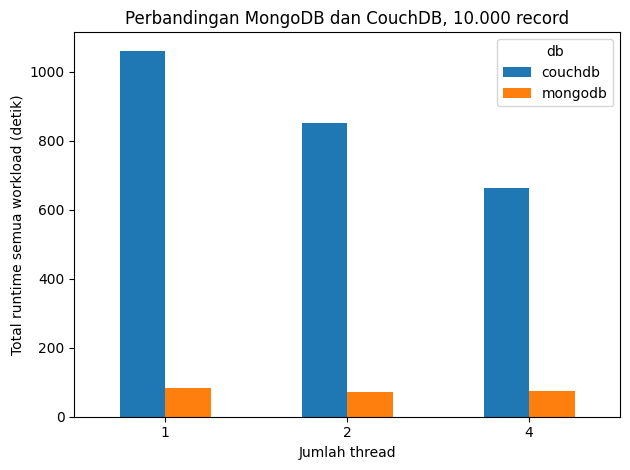

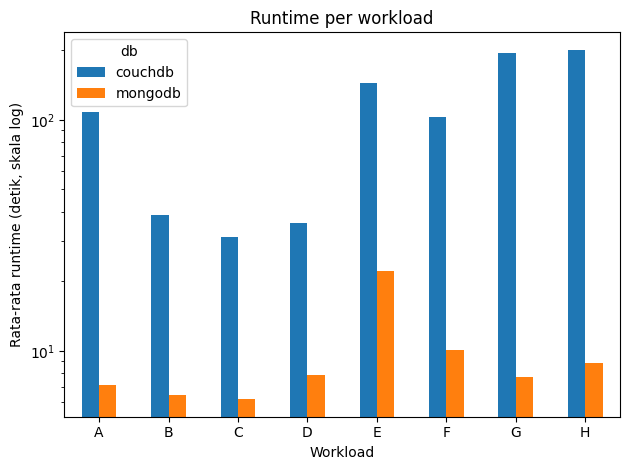

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

m = pd.read_csv("/content/hasil_mongodb.csv")
c = pd.read_csv("/content/hasil_couchdb.csv")
print("Kolom MongoDB :", list(m.columns))
print("Kolom CouchDB :", list(c.columns))

df = pd.concat([m, c], ignore_index=True)
df["workload"] = (df["workload"].astype(str).str.lower()
                  .str.replace("workload", "", regex=False).str.upper())

cek = df.groupby(["db", "workload", "threads"]).size().unstack("db")
print("\nJumlah ulangan per kombinasi (harus 3 semua):")
print(cek)

rata = (df.groupby(["db", "workload", "threads"])["runtime_s"]
          .mean().round(2).reset_index())
tabel = rata.pivot_table(index="workload", columns=["db", "threads"], values="runtime_s")
print("\nRata-rata runtime (detik):")
print(tabel)
tabel.to_csv("/content/tabel_rata_rata.csv")

total = (df.groupby(["db", "threads", "rep"])["runtime_s"].sum()
           .groupby(["db", "threads"]).mean().round(2))
print("\nTotal runtime semua workload (detik):")
print(total)

ax = total.unstack("db").plot(kind="bar", rot=0)
ax.set_ylabel("Total runtime semua workload (detik)")
ax.set_xlabel("Jumlah thread")
ax.set_title("Perbandingan MongoDB dan CouchDB, 10.000 record")
plt.tight_layout()
plt.savefig("/content/grafik_total.png", dpi=150)

per_wl = df.groupby(["workload", "db"])["runtime_s"].mean().unstack("db")
ax2 = per_wl.plot(kind="bar", rot=0, logy=True)
ax2.set_ylabel("Rata-rata runtime (detik, skala log)")
ax2.set_xlabel("Workload")
ax2.set_title("Runtime per workload")
plt.tight_layout()
plt.savefig("/content/grafik_per_workload.png", dpi=150)

plt.show()

In [37]:
   !zip -j /content/hasil_eksperimen.zip /content/hasil_mongodb.csv /content/hasil_couchdb.csv /content/tabel_rata_rata.csv /content/grafik_total.png /content/grafik_per_workload.png

  adding: hasil_mongodb.csv (deflated 79%)
  adding: hasil_couchdb.csv (deflated 77%)
  adding: tabel_rata_rata.csv (deflated 42%)
  adding: grafik_total.png (deflated 18%)
  adding: grafik_per_workload.png (deflated 21%)


In [38]:
import os, platform
print("CPU core :", os.cpu_count())
print("Python   :", platform.python_version())
print("OS       :", platform.platform())
!lscpu | grep "Model name"
!free -h | head -2
!java -version 2>&1 | head -1
!curl -s http://127.0.0.1:5984/

CPU core : 2
Python   : 3.13.16
OS       : Linux-6.6.122+-x86_64-with-glibc2.39
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.4Gi       8.8Gi        16Mi       2.8Gi        11Gi
[0.010s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
{"couchdb":"Welcome","version":"3.5.3","git_sha":"7a1f97558","uuid":"aedbb782c66e4a1e1d18209e7823b2c0","features":["access-ready","partitioned","pluggable-storage-engines","reshard","scheduler"],"vendor":{"name":"The Apache Software Foundation"}}


In [39]:
!ls /content | grep -i mongodb
!/content/mongodb-linux-*/bin/mongod --version | head -2

hasil_mongodb.csv
mongodb-linux-x86_64-ubuntu2204-6.0.16
db version v6.0.16
Build Info: {


In [40]:
!java -version 2>&1 | grep version

openjdk version "21.0.12.1" 2026-08-18
